# Text2SQL
In this notebook, a Text2SQL system is created which generates valid SQL queries that aim to retrieve data to answer the question of the user. Data used to test and evaluate this system is the [Spider 1.0](https://yale-lily.github.io/spider) dataset. This dataset consists of user questions, golden SQL queries to extract to data to answer the question and the underlying SQLite databases and tables that contain the data.

## Import libraries

In [1]:
import sqlite3
from pathlib import Path
import json
from functools import cache
import ollama
import sqlglot
from sqlglot import exp
from langgraph.config import get_config
from langgraph.graph import END, START, StateGraph
from langgraph.runtime import Runtime
from typing import TypedDict
import time
from dataclasses import dataclass
from IPython.display import Image, display
import pandas as pd
from collections import Counter

## Load dataset used for testing

Load the Spider 1.0 dataset as initial testing data:

In [2]:
DATABASE_DIR = Path("../data/spider/database")

In [3]:
SPIDER_DIR = Path("../data/spider")

with open(SPIDER_DIR / "train_spider.json") as f:
    train_data = json.load(f)

with open(SPIDER_DIR / "dev.json") as f:
    dev_data = json.load(f)

with open(SPIDER_DIR / "tables.json") as f:
    tables_data = json.load(f)

print("Train:", len(train_data))
print("Dev:", len(dev_data))
print("Schemas:", len(tables_data))

Train: 7000
Dev: 1034
Schemas: 166


Inspect one example:

In [4]:
example = dev_data[0]

print("QUESTION:")
print(example["question"])

print("\nGOLD SQL:")
print(example["query"])

print("\nDATABASE:")
print(example["db_id"])

QUESTION:
How many singers do we have?

GOLD SQL:
SELECT count(*) FROM singer

DATABASE:
concert_singer


## Define SQLite helper functions

Define function to connect the SQLite database and run the SQL query:

In [5]:
def connect(db_id: str) -> sqlite3.Connection:
    """Open the database read-only, so nothing can be modified even if validation misses something."""
    path = DATABASE_DIR / db_id / f"{db_id}.sqlite"
    if not path.exists():
        raise FileNotFoundError(path)
    conn = sqlite3.connect(f"file:{path}?mode=ro", uri=True)
    conn.text_factory = lambda b: b.decode(errors="replace")  # some Spider DBs contain invalid UTF-8
    return conn

QUERY_TIMEOUT_S = 120.0
def execute_sql(sql: str, db_id: str) -> tuple[list[str], list[tuple]]:
    """Run the query with a time limit and return all rows as (columns, rows)."""
    with connect(db_id) as conn:
        deadline = time.monotonic() + QUERY_TIMEOUT_S
        conn.set_progress_handler(lambda: time.monotonic() > deadline, 10_000)
        cursor = conn.execute(sql)
        rows = cursor.fetchall()
        columns = [d[0] for d in cursor.description]
    return columns, rows

In [6]:
gold_result = execute_sql(
    example["query"],
    example["db_id"]
)

gold_result

(['count(*)'], [(6,)])

Define function to get schema for all tables of a database:

In [7]:
@cache
def get_schema(db_id: str) -> str:
    """Get the schema incl. primary and foreign keys, e.g. `singer(Singer_ID INT PK, Name TEXT)`."""
    with connect(db_id) as conn:
        tables = [
            row[0]
            for row in conn.execute(
                "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name"
            )
        ]
        lines = []
        for table in tables:
            cols = [
                f"{name} {dtype}{' PK' if pk else ''}".strip()
                for _, name, dtype, _, _, pk in conn.execute(f'PRAGMA table_info("{table}")')
            ]
            lines.append(f"{table}({', '.join(cols)})")
            for fk in conn.execute(f'PRAGMA foreign_key_list("{table}")'):
                lines.append(f"  FK {table}.{fk[3]} -> {fk[2]}.{fk[4]}")
    return "\n".join(lines)

In [8]:
schema = get_schema(example["db_id"])
schema

'concert(concert_ID INT PK, concert_Name TEXT, Theme TEXT, Stadium_ID TEXT, Year TEXT)\n  FK concert.Stadium_ID -> stadium.Stadium_ID\nsinger(Singer_ID INT PK, Name TEXT, Country TEXT, Song_Name TEXT, Song_release_year TEXT, Age INT, Is_male bool)\nsinger_in_concert(concert_ID INT PK, Singer_ID TEXT PK)\n  FK singer_in_concert.Singer_ID -> singer.Singer_ID\n  FK singer_in_concert.concert_ID -> concert.concert_ID\nstadium(Stadium_ID INT PK, Location TEXT, Name TEXT, Capacity INT, Highest INT, Lowest INT, Average INT)'

## Use LLM to write SQL based on question and schema

In [9]:
OLLAMA_HOST = "http://localhost:11434"
MODEL_ID = "qwen3:8b"

In [10]:
llm = ollama.Client(host=OLLAMA_HOST)

LLM_CALLS: list[dict] = []  # used to log LLM calls

def current_node() -> str:
    """Name of the graph node that is calling the LLM or "direct" when called outside the graph."""
    try:
        return get_config()["metadata"]["langgraph_node"]
    except (RuntimeError, KeyError):
        return "direct"


def ask(system: str, prompt: str) -> str:
    start = time.perf_counter()
    response = llm.chat(
        model=MODEL_ID,
        messages=[{"role": "system", "content": system}, {"role": "user", "content": prompt}],
        think=False,
        options={"temperature": 0},
    )
    output = response.message.content.strip()
    LLM_CALLS.append(
        {
            "node": current_node(),
            "seconds": time.perf_counter() - start,
            "input_tokens": response.prompt_eval_count or 0,
            "output_tokens": response.eval_count or 0,
            "output": output,
        }
    )
    return output

Define SQL generator prompt:

In [11]:
sql_generator_prompt = """
You are a text-to-SQL specialist.

Your task is to translate a natural-language question into
a correct SQLite SQL query.

Rules:

1. Only generate SELECT statements.
2. Use only tables and columns present in the provided schema.
3. Do not invent tables or columns.
4. Prefer simple SQL when possible.
5. Return ONLY the SQL query.
6. Do not use markdown code fences.
7. Do not explain your answer.
"""

In [12]:
def create_prompt(question: str, schema: str) -> str:
    return f"""
Database schema:
{schema}

User question:
{question}
"""

In [13]:
generated_sql = ask(sql_generator_prompt, create_prompt(example["question"], schema))
generated_sql

'SELECT COUNT(*) FROM singer;'

Define function to test if valid SQL query was created:

In [14]:
def validate_sql(sql: str, db_id: str) -> list[str]:
    """Validate the generated SQL query.
    Returns a list of errors or an empty list which means the query is valid."""
    if not sql:
        return ["SQL is empty."]
    try:
        statements = [s for s in sqlglot.parse(sql, dialect="sqlite") if s is not None]
    except sqlglot.errors.ParseError as e:
        return [f"Parse error: {e}"]
    if len(statements) != 1:
        return ["Exactly one SQL statement is required."]
    if not isinstance(statements[0], exp.Query):  # SELECT, WITH ... SELECT, UNION, ...
        return ["Only SELECT queries are allowed."]

    # SQLite compiles the query without running it: catches unknown tables/columns, bad functions, ...
    with connect(db_id) as conn:
        try:
            conn.execute(f"EXPLAIN QUERY PLAN {sql}")
        except sqlite3.Error as e:
            return [f"SQLite error: {e}"]
    return []

In [15]:
validate_sql(generated_sql, example["db_id"])

[]

## Define Text2SQL graph
To have a Text2SQL system we are building a graph using langgraph. The graph will consist of the following six nodes:
1. SQL generator: Based on the provided question and schema this node creates a SQL query to get the relevant data to answer the question.
2. Validator: This node uses the previously defined function to determine if the generated SQL query is valid.
3. Executor: This node executes the generated SQL query and returns the result columns and rows.
4. Checker: Verifies if the result of the query correctly answers the question of the user.
4. Corrector: The corrector will try to fix errors in the generated SQL query.
5. Explainer: This node will answer the initial question based on the result of the generated SQL query.

The workflow for this graph looks the following:

![alt text](../documentation/graph_workflow.png "Title")

The idea of the workflow is that if any errors occur the corrector node is called to try to fix these errors. For this a limit on how often the corrector is called can be set to prevent infinite loops. Additionally, the explainer step and using a LLM to check can be disabled as well.

### State definition

Define the state shared in each node during execution:

In [16]:
class State(TypedDict, total=False):
    # input
    question: str
    db_id: str
    schema: str
    # working state
    sql: str
    errors: list[str]
    attempts: int
    columns: list[str]
    rows: list[tuple]  # full result
    exec_error: str | None
    confirmed: bool  # corrector returned the query unchanged -> accept it
    # output
    answer: str | None

### Prompt and node function definition

Define the prompts for the remaining nodes (for the corrector we will re-use the prompt of the generator node):

In [17]:
checker_prompt = """
Your task is to verify whether a SQL query and its result correctly answer the question of the user.

Rules:
1. Reply with exactly `OK` if they do. Otherwise reply `WRONG: <one sentence naming the mistake>`.
2. Only flag clear mistakes: wrong or missing columns, missing or wrong filter, wrong aggregation, wrong join,
wrong ordering or limit.
3. When in doubt, reply `OK`.
"""

explainer_prompt = """
You explain SQL query results to users.

Rules:
1. Only describe facts supported by the query result.
2. Do not invent information.
3. Be concise.
4. Mention important numbers and trends.
5. If there are no rows, explicitly say so.
"""

Define the functions for each node:

In [18]:
MAX_PROMPT_ROWS = 50  # rows shown to the LLM (explainer); the executor keeps all rows
MAX_CHECK_ROWS = 20  # rows shown to the LLM judge in the checker


@dataclass(frozen=True)
class Settings:
    """Per-run settings, passed to the graph as runtime context."""
    check_with_llm: bool = True  # LLM judge in the checker; False = only deterministic checks
    max_corrections: int = 2  # total corrector runs (invalid SQL + wrong results), then -> failure / give_up
    explain: bool = True  # run the explainer at the end

In [19]:
def generate(state: State) -> State:
    prompt = create_prompt(state["question"], state["schema"])
    return {"sql": ask(sql_generator_prompt, prompt)}

def validate(state: State) -> State:
    return {"errors": validate_sql(state["sql"], state["db_id"])}

def correct(state: State) -> State:
    generation_prompt = create_prompt(state["question"], state["schema"])
    problems = "\n".join(state["errors"])
    prompt = f"""
    {generation_prompt}

    Generated query: {state["sql"]}

    Problems: {problems}
    """
    new_sql = ask(sql_generator_prompt, prompt)
    unchanged = " ".join(new_sql.split()).rstrip(";") == " ".join(state["sql"].split()).rstrip(";")
    return {"sql": new_sql, "attempts": state["attempts"] + 1, "confirmed": unchanged}

def execute(state: State) -> State:
    try:
        columns, rows = execute_sql(state["sql"], state["db_id"])
    except sqlite3.Error as e:  # e.g. timeout ("interrupted") -> checker sends it to the corrector
        return {"columns": [], "rows": [], "exec_error": str(e)}
    return {"columns": columns, "rows": rows, "exec_error": None}

def format_rows(columns: list[str], rows: list[tuple], limit: int = MAX_PROMPT_ROWS) -> str:
    """Convert output of SQL query to easy to read format for LLM prompts.
    Use limit to limit the number of rows shown in the prompt."""
    lines = [" | ".join(columns)] + [" | ".join(map(str, r)) for r in rows[:limit]]
    if len(rows) > limit:
        lines.append(f"... showing {limit} of {len(rows)} rows")
    return "\n".join(lines)

def check(state: State, runtime: Runtime[Settings]) -> State:
    """Catch valid-but-wrong queries. Cheap deterministic checks first, then the optional LLM judge."""
    if state["exec_error"]:
        return {"errors": [f"Execution error: {state['exec_error']}"]}
    if state.get("confirmed"):  # the corrector kept the query as it was -> trust it
        return {"errors": []}
    if not state["rows"]:
        return {
            "errors": [
                "The query returned no rows. Check filter values (spelling, case, format) and join conditions. "
                "If no rows is really the correct answer, return the query unchanged."
            ]
        }
    if all(value is None for row in state["rows"] for value in row):
        return {"errors": ["The query returned only NULL values."]}
    if not runtime.context.check_with_llm:
        return {"errors": []}

    result = format_rows(state["columns"], state["rows"], limit=MAX_CHECK_ROWS)
    generation_prompt = create_prompt(state["question"], state["schema"])
    prompt = f"""
    {generation_prompt}

    Generated query: {state["sql"]}

    Result: {result}
    """
    verdict = ask(checker_prompt, prompt)
    return {"errors": [] if verdict.strip("`*. ").upper().startswith("OK") else [verdict]}

def explain(state: State) -> State:
    result = format_rows(state["columns"], state["rows"])

    prompt = f"""
    Question: {state["question"]}

    Generated query: {state["sql"]}

    Result: {result}
    """
    if state["errors"]:  # reached via give_up
        prompt += "\n\nNote: a reviewer suspects this result is wrong: " + " ".join(state["errors"])
        prompt += "\nAnswer from the result, but tell the user it may be inaccurate."
    return {"answer": ask(explainer_prompt, prompt)}

def fail(state: State) -> State:
    return {"answer": f"Could not produce a working query after {state['attempts']} corrections: {state['errors']}"}

### Define the graph

In [20]:
def route_after_validate(state: State, runtime: Runtime[Settings]) -> str:
    if not state["errors"]:
        return "executor"
    return "corrector" if state["attempts"] < runtime.context.max_corrections else "failure"


def route_after_check(state: State, runtime: Runtime[Settings]) -> str:
    done = "explainer" if runtime.context.explain else END
    if not state["errors"]:
        return done
    if state["attempts"] < runtime.context.max_corrections:
        return "corrector"
    # budget used up: answer with a caveat if we have data (give_up), otherwise fail
    return done if state["rows"] else "failure"


builder = StateGraph(State, context_schema=Settings)
builder.add_node("generator", generate)
builder.add_node("validator", validate)
builder.add_node("corrector", correct)
builder.add_node("executor", execute)
builder.add_node("checker", check)
builder.add_node("explainer", explain)
builder.add_node("failure", fail)

builder.add_edge(START, "generator")
builder.add_edge("generator", "validator")
builder.add_conditional_edges("validator", route_after_validate, ["executor", "corrector", "failure"])
builder.add_edge("corrector", "validator")
builder.add_edge("executor", "checker")
builder.add_conditional_edges("checker", route_after_check, ["explainer", "corrector", "failure", END])
builder.add_edge("explainer", END)
builder.add_edge("failure", END)

graph = builder.compile()

Visualize the graph:

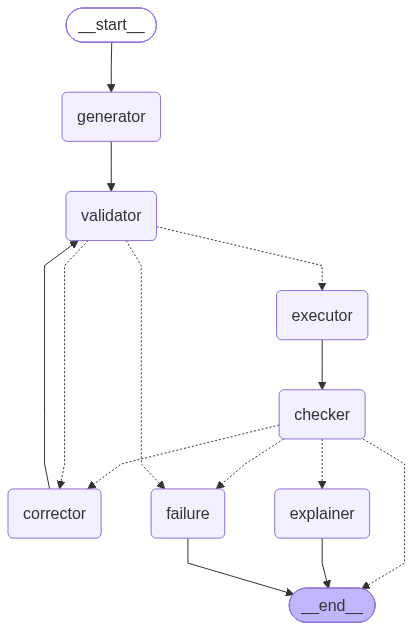

In [21]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_mermaid())

In [22]:
def text2sql(question: str, db_id: str, settings: Settings | None = None) -> State:
    """Run the graph for a specific question."""
    settings = settings or Settings()  # not a default argument: ruff B008
    return graph.invoke(
        {"question": question, "db_id": db_id, "schema": get_schema(db_id), "attempts": 0, "answer": None},
        context=settings,
        # each correction adds at most 4 steps; LangGraph's default limit (25) would cap max_corrections at 5
        config={"recursion_limit": 4 * settings.max_corrections + 10},
    )

In [23]:
out = text2sql(example["question"], example["db_id"])

print("SQL:   ", out["sql"])
print("ROWS:  ", out.get("rows"))
print("QUESTION:", example["question"])
print("ANSWER:", out["answer"])

SQL:    SELECT COUNT(*) FROM singer;
ROWS:   [(6,)]
QUESTION: How many singers do we have?
ANSWER: There are 6 singers in total.


In [24]:
out

{'question': 'How many singers do we have?',
 'db_id': 'concert_singer',
 'schema': 'concert(concert_ID INT PK, concert_Name TEXT, Theme TEXT, Stadium_ID TEXT, Year TEXT)\n  FK concert.Stadium_ID -> stadium.Stadium_ID\nsinger(Singer_ID INT PK, Name TEXT, Country TEXT, Song_Name TEXT, Song_release_year TEXT, Age INT, Is_male bool)\nsinger_in_concert(concert_ID INT PK, Singer_ID TEXT PK)\n  FK singer_in_concert.Singer_ID -> singer.Singer_ID\n  FK singer_in_concert.concert_ID -> concert.concert_ID\nstadium(Stadium_ID INT PK, Location TEXT, Name TEXT, Capacity INT, Highest INT, Lowest INT, Average INT)',
 'sql': 'SELECT COUNT(*) FROM singer;',
 'errors': [],
 'attempts': 0,
 'columns': ['COUNT(*)'],
 'rows': [(6,)],
 'exec_error': None,
 'answer': 'There are 6 singers in total.'}

## Evaluation on the spider dataset
In this section the system is evaluated based on the Spider 1.0 dataset. To measure how much the system and it's separate components improve the results the following three different variants are tested:
1. Simple approach without the graph: Provide the question and schema to the LLM.
2. Graph without LLM checker: During the check step only apply the deterministic checks and skip the LLM judge.
3. Full graph.

For all variants the explainer step is skipped. As the LLM for the comparison qwen3:8b was chosen.

Define function to check if the result is correct by checking if same results are returned based on the gold query from the spider dataset. The order of the rows only matters if the gold query uses ORDER BY.

In [26]:
def is_correct(sql: str, example: dict) -> bool:
    try:
        predicted = execute_sql(sql, example["db_id"])[1]
        gold = execute_sql(example["query"], example["db_id"])[1]
    except Exception:
        return False
    if "order by" in example["query"].lower():
        return predicted == gold
    return Counter(predicted) == Counter(gold)

Define functions to run the different variants:

In [27]:
def run_baseline(example: dict) -> dict:
    start = time.perf_counter()
    sql = ask(sql_generator_prompt, create_prompt(example["question"], get_schema(example["db_id"])))
    return {"sql": sql, "failed": False, "llm_calls": 1, "latency": time.perf_counter() - start}


def run_graph(example: dict, settings: Settings) -> dict:
    LLM_CALLS.clear()
    start = time.perf_counter()
    out = text2sql(example["question"], example["db_id"], settings)
    return {
        "sql": out["sql"],
        "failed": out["answer"] is not None,  # with explain=False only the failure node sets an answer
        "llm_calls": len(LLM_CALLS),
        "latency": time.perf_counter() - start,
        "errors": out["errors"],  # last problems found
        "steps": [(c["node"], c["output"]) for c in LLM_CALLS],  # every generated query / verdict
    }

Run all questions:

In [28]:
variations = {
    "graph_no_judge": Settings(check_with_llm=False, explain=False),
    "graph_full": Settings(check_with_llm=True, explain=False),
}

In [29]:
ask("Reply with OK.", "OK")  # warm-up: the first call loads the model

rows = []
for i, example in enumerate(dev_data):
    results = {"baseline": run_baseline(example)}
    for name, settings in variations.items():
        results[name] = run_graph(example, settings)

    for system, result in results.items():
        correct = not result["failed"] and is_correct(result["sql"], example)
        rows.append(
            {
                "id": i,
                "question": example["question"],
                "gold_sql": example["query"],
                "system": system,
                **result,
                "correct": correct,
            }
        )
    print(f"{i + 1}/{len(dev_data)}", end="\r")

In [30]:
df = pd.DataFrame(rows)

In [31]:
df.to_json("spider_dev_eval.jsonl", orient="records", lines=True)

In [40]:
df = pd.read_json("spider_dev_eval.jsonl", lines=True)
df

,id,question,gold_sql,system,sql,failed,llm_calls,latency,correct,errors,steps
0,0,How many singers do we have?,SELECT count(*) FROM singer,baseline,SELECT COUNT(*) FROM singer;,False,1,0.294565,True,None,None
1,0,How many singers do we have?,SELECT count(*) FROM singer,graph_no_judge,SELECT COUNT(*) FROM singer;,False,1,0.292989,True,[],"[[generator, SELECT COUNT(*) FROM singer;]]"
2,0,How many singers do we have?,SELECT count(*) FROM singer,graph_full,SELECT COUNT(*) FROM singer;,False,2,0.410320,True,[],"[[generator, SELECT COUNT(*) FROM singer;], [c..."
3,1,What is the total number of singers?,SELECT count(*) FROM singer,baseline,SELECT COUNT(DISTINCT Singer_ID) FROM singer;,False,1,0.616779,True,None,None
4,1,What is the total number of singers?,SELECT count(*) FROM singer,graph_no_judge,SELECT COUNT(DISTINCT Singer_ID) FROM singer;,False,1,0.533557,True,[],"[[generator, SELECT COUNT(DISTINCT Singer_ID) ..."
...,...,...,...,...,...,...,...,...,...,...,...
3097,1032,Show the property type descriptions of propert...,SELECT T2.property_type_description FROM Prope...,graph_no_judge,SELECT Ref_Property_Types.property_type_descri...,False,1,1.320810,False,[],"[[generator, SELECT Ref_Property_Types.propert..."
3098,1032,Show the property type descriptions of propert...,SELECT T2.property_type_description FROM Prope...,graph_full,SELECT Ref_Property_Types.property_type_descri...,False,2,2.070799,False,[],"[[generator, SELECT Ref_Property_Types.propert..."
3099,1033,What are the names of properties that are eith...,SELECT property_name FROM Properties WHERE pro...,baseline,SELECT property_name\nFROM Properties\nWHERE p...,False,1,1.200128,False,None,None
3100,1033,What are the names of properties that are eith...,SELECT property_name FROM Properties WHERE pro...,graph_no_judge,SELECT property_name\nFROM Properties\nWHERE p...,False,2,4.184074,False,[],"[[generator, SELECT property_name\nFROM Proper..."


Analyze results:

In [33]:
df.groupby("system").agg(
    accuracy=("correct", "mean"),
    failed=("failed", "mean"),
    llm_calls=("llm_calls", "mean"),
    latency_median=("latency", "median"),
    latency_p90=("latency", lambda s: s.quantile(0.9)),
)

,accuracy,failed,llm_calls,latency_median,latency_p90
system,,,,,
baseline,0.676015,0.000000,1.000000,1.269488,2.352183
graph_full,0.689555,0.012573,2.162476,1.779477,4.202004
graph_no_judge,0.682785,0.007737,1.130561,1.224945,2.970160


This shows that a slight accuracy improvement can be achieved by using the graph workflow. Additionally, using the full graph and not skipping the LLM judge further improves the results. Of course this comes with a trade-off latency wise and also additional costs because of more LLM calls.

In [34]:
correct = df.pivot(index="id", columns="system", values="correct")
for name in variations:
    fixed = (~correct["baseline"] & correct[name]).sum()
    broken = (correct["baseline"] & ~correct[name]).sum()
    print(f"{name}: fixed {fixed}, broken {broken}")

graph_no_judge: fixed 7, broken 0
graph_full: fixed 17, broken 3


In [35]:
broken = correct.index[correct["baseline"] & ~correct["graph_full"]]

for _, r in df[(df.system == "graph_full") & df.id.isin(broken)].iterrows():
    print(f"\nQ: {r.question}\nGOLD: {r.gold_sql}\nERRORS: {r.errors}")
    for node, output in r.steps:
        print(f"  [{node}] {output}")


Q: What are the ids of documents that contain the paragraph text 'Brazil' and 'Ireland'?
GOLD: SELECT document_id FROM Paragraphs WHERE paragraph_text  =  'Brazil' INTERSECT SELECT document_id FROM Paragraphs WHERE paragraph_text  =  'Ireland'
ERRORS: []
  [generator] SELECT DISTINCT Documents.Document_ID
FROM Documents
JOIN Paragraphs ON Documents.Document_ID = Paragraphs.Document_ID
WHERE Paragraphs.Paragraph_Text = 'Brazil' OR Paragraphs.Paragraph_Text = 'Ireland';
  [checker] WRONG: missing filter for both 'Brazil' and 'Ireland'
  [corrector] SELECT DISTINCT Documents.Document_ID
FROM Documents
JOIN Paragraphs ON Documents.Document_ID = Paragraphs.Document_ID
WHERE Paragraphs.Paragraph_Text = 'Brazil' AND Paragraphs.Paragraph_Text = 'Ireland';
  [corrector] SELECT DISTINCT Documents.Document_ID
FROM Documents
JOIN Paragraphs ON Documents.Document_ID = Paragraphs.Document_ID
WHERE Paragraphs.Paragraph_Text = 'Brazil' AND Paragraphs.Paragraph_Text = 'Ireland';

Q: Which African coun

Check if the generated queries can be run:

In [47]:
def query_rows(sql: str, db_id: str) -> list[tuple] | None:
    try:
        return execute_sql(sql, db_id)[1]
    except Exception:
        return None
df["executable"] = [query_rows(r.sql, dev_data[r.id]["db_id"]) is not None for r in df.itertuples()]

In [59]:
baseline = df[df["system"] == "baseline"].reset_index(drop=True)
graph_no_judge = df[df["system"] == "graph_no_judge"].reset_index(drop=True)
graph_full = df[df["system"] == "graph_full"].reset_index(drop=True)

In [60]:
print(f"Number of non executable queries - baseline: ", len(baseline[~baseline["executable"]]))
print(f"Number of non executable queries - graph_no_judge: ", len(graph_no_judge[~graph_no_judge["executable"]]) )
print(f"Number of non executable queries - graph_full: ", len(graph_full[~graph_full["executable"]]))

Number of non executable queries - baseline:  23
Number of non executable queries - graph_no_judge:  8
Number of non executable queries - graph_full:  10


Try to measure the benefit of the LLM judge by checking for every query if it was correct and if the judge flagged it or not:

In [61]:
judge = []
for i, r in graph_full.iterrows():
    sql = None
    for node, output in r.steps:
        if node in ("generator", "corrector"):
            sql = output
        elif node == "checker":
            flagged = not output.strip("`*. ").upper().startswith("OK")
            judge.append({"sql_correct": is_correct(sql, dev_data[i]), "flagged": flagged})
judge = pd.DataFrame(judge)

False alarm rate: Share of correct queries the judge incorrectly flags

Catch rate: Share of wrong queries the judge correctly flags

In [64]:
print(f"False-alarm rate: {judge[judge["sql_correct"]]["flagged"].mean():.1%}")
print(f"Catch rate:       {judge[~judge["sql_correct"]]["flagged"].mean():.1%}")
pd.crosstab(judge["sql_correct"], judge["flagged"], margins=True)

False-alarm rate: 4.1%
Catch rate:       19.7%


flagged,False,True,All
sql_correct,,,
False,237,58,295
True,658,28,686
All,895,86,981


Each wrong answer (not ended in the failure node) is put into one category by comparing its rows with the gold rows:

| Category | Meaning |
|---|---|
| not executable | the query doesn't run |
| empty result | no rows, but the gold query returns rows |
| extra columns | all gold columns are there, plus more (e.g. ID + name) |
| different columns | different number of columns, gold columns not all included |
| same rows, different duplicates/order | same distinct rows; duplicates or row order differ |
| same values, different column order | same rows, only the column order differs (not a real error, `is_correct` compares columns in order) |
| too many rows | gold rows plus extra rows, often a missing `DISTINCT` or a duplicating join |
| too few rows | a subset of the gold rows |
| different values | everything else: wrong filter, join or aggregation |

In [65]:
def error_category(sql: str, example: dict) -> str:
    gold = query_rows(example["query"], example["db_id"])
    pred = query_rows(sql, example["db_id"])
    if pred is None:
        return "not executable"
    if not pred:
        return "empty result"
    if gold and len(pred[0]) != len(gold[0]):
        gold_columns = [set(column) for column in zip(*gold)]
        pred_columns = [set(column) for column in zip(*pred)]
        if all(column in pred_columns for column in gold_columns):
            return "extra columns"
        return "different columns"
    if set(pred) == set(gold):
        return "same rows, different duplicates/order"
    if Counter(tuple(sorted(map(str, r))) for r in pred) == Counter(tuple(sorted(map(str, r))) for r in gold):
        return "same values, different column order"
    if set(gold) < set(pred):
        return "too many rows"
    if set(pred) < set(gold):
        return "too few rows"
    return "different values"


wrong = df[~df["correct"] & ~df["failed"]].copy()
wrong["category"] = [error_category(r.sql, dev_data[r.id]) for r in wrong.itertuples()]
pd.crosstab(wrong["category"], wrong["system"], margins=True).sort_values("graph_full", ascending=False)

system,baseline,graph_full,graph_no_judge,All
category,,,,
All,335,308,320,963
different values,103,97,104,304
empty result,42,47,45,134
"same values, different column order",46,46,46,138
extra columns,41,40,41,122
too many rows,38,36,41,115
different columns,15,16,15,46
"same rows, different duplicates/order",12,13,12,37
too few rows,15,13,16,44


Look at a few examples of one category:

In [66]:
for r in wrong[(wrong["system"] == "graph_full") & (wrong["category"] == "extra columns")].head(5).itertuples():
    print(f"\nQ: {r.question}\nGOLD: {r.gold_sql}\nPRED: {' '.join(r.sql.split())}")


Q: Which year has most number of concerts?
GOLD: SELECT YEAR FROM concert GROUP BY YEAR ORDER BY count(*) DESC LIMIT 1
PRED: SELECT Year, COUNT(*) AS num_concerts FROM concert GROUP BY Year ORDER BY num_concerts DESC LIMIT 1;

Q: What is the year that had the most concerts?
GOLD: SELECT YEAR FROM concert GROUP BY YEAR ORDER BY count(*) DESC LIMIT 1
PRED: SELECT Year, COUNT(*) AS num_concerts FROM concert GROUP BY Year ORDER BY num_concerts DESC LIMIT 1;

Q: Show the name and theme for all concerts and the number of singers in each concert.
GOLD: SELECT T2.concert_name ,  T2.theme ,  count(*) FROM singer_in_concert AS T1 JOIN concert AS T2 ON T1.concert_id  =  T2.concert_id GROUP BY T2.concert_id
PRED: SELECT concert.concert_ID, concert.concert_Name, concert.Theme, COUNT(singer_in_concert.Singer_ID) AS num_singers FROM concert JOIN singer_in_concert ON concert.concert_ID = singer_in_concert.concert_ID GROUP BY concert.concert_ID;

Q: What are the names , themes , and number of singers 